# Phase 0: can embeddings tell individual animals apart?

We compare **CLIP ViT-B/16** and **DINOv2 ViT-B/14**, each on the full image and on a YOLO crop. Embeddings are produced by `python -m src.embed_all` and cached in `outputs/embeddings/`.

Every query is ranked against the other images of its dataset **plus all Oxford-IIIT images of the same species** as distractors (thousands of animals that look similar but are different). That mimics the app, where a sighting is compared to every same-species report nearby.

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import metrics

EMB = Path('../outputs/embeddings'); OUT = Path('../outputs')
MODELS, CROPS = ['clip-b16', 'dinov2-b14'], ['full', 'crop']
IDENTITY_SETS = [n for n in ['dogfacenet', 'petfinder', 'petface_cat', 'petface_dog', 'own']
                 if (EMB / f'{n}_index.csv').exists()]

def load(name, model, crop):
    return pd.read_csv(EMB / f'{name}_index.csv'), np.load(EMB / f'{name}_{model}_{crop}.npy')

IDENTITY_SETS

['dogfacenet', 'petfinder', 'own']

## 1. Detection rate
Share of images where YOLO found a cat or dog. In the app, a photo without a detection is rejected as unusable.

In [2]:
rows = []
for name in ['oxford', *IDENTITY_SETS]:
    idx = pd.read_csv(EMB / f'{name}_index.csv')
    rows.append({'dataset': name, 'images': len(idx),
                 'identities': idx['identity'].nunique(),
                 'detected': round(idx['det_conf'].notna().mean(), 3),
                 'species_agrees': round((idx['det_species'] == idx['species']).mean(), 3)})
detection = pd.DataFrame(rows); detection

,dataset,images,identities,detected,species_agrees
0,oxford,7390,0,0.975,0.956
1,dogfacenet,8363,1393,0.919,0.889
2,petfinder,48542,10855,0.979,0.933
3,own,5,1,1.000,1.000


## 2. Same-individual retrieval and verification
- **top1 / top5**: a photo of the same animal is ranked first / in the first five.
- **AUC**: how well the similarity score alone separates same-animal pairs from different-animal pairs (1.0 = perfect).

In [3]:
results, pairs = [], {}
for name in IDENTITY_SETS:
    for model in MODELS:
        for crop in CROPS:
            df, emb = load(name, model, crop)
            ox_df, ox_emb = load('oxford', model, crop)
            keep = ox_df['species'].isin(df['species'].unique()).to_numpy()
            all_df = pd.concat([df, ox_df[keep]], ignore_index=True)
            all_emb = np.vstack([emb, ox_emb[keep]])
            top = metrics.retrieval_topk(all_emb, all_df)
            pos, neg = metrics.pair_similarities(all_emb, all_df)
            pairs[name, model, crop] = (pos, neg)
            results.append({'dataset': name, 'model': model, 'crop': crop,
                            'distractors': int(keep.sum()), **top,
                            'auc': metrics.verification_auc(pos, neg)})
results = pd.DataFrame(results).round(3)
results.to_csv(OUT / 'retrieval_results.csv', index=False)
results

,dataset,model,crop,distractors,queries,top1,top5,auc
0,dogfacenet,clip-b16,full,4990,8363,0.614,0.760,0.917
1,dogfacenet,clip-b16,crop,4990,8363,0.582,0.736,0.909
2,dogfacenet,dinov2-b14,full,4990,8363,0.909,0.966,0.995
3,dogfacenet,dinov2-b14,crop,4990,8363,0.911,0.967,0.995
4,petfinder,clip-b16,full,7390,48542,0.493,0.622,0.847
5,petfinder,clip-b16,crop,7390,48542,0.400,0.528,0.832
6,petfinder,dinov2-b14,full,7390,48542,0.627,0.750,0.935
7,petfinder,dinov2-b14,crop,7390,48542,0.583,0.709,0.923
8,own,clip-b16,full,2400,5,1.000,1.000,0.858
9,own,clip-b16,crop,2400,5,1.000,1.000,0.856


## 3. Breed clustering (Oxford-IIIT)
How often the nearest neighbour is the same breed. High values mean the model groups animals by breed, which is how it can confuse two different animals of the same breed.

In [4]:
breed = pd.DataFrame([{'model': m, 'crop': c,
                       'breed_top1': metrics.breed_top1(load('oxford', m, c)[1], load('oxford', m, c)[0])}
                      for m in MODELS for c in CROPS]).round(3)
breed

,model,crop,breed_top1
0,clip-b16,full,0.854
1,clip-b16,crop,0.870
2,dinov2-b14,full,0.948
3,dinov2-b14,crop,0.948


## 4. Similarity distributions
Same-animal pairs versus random different-animal pairs (same species).

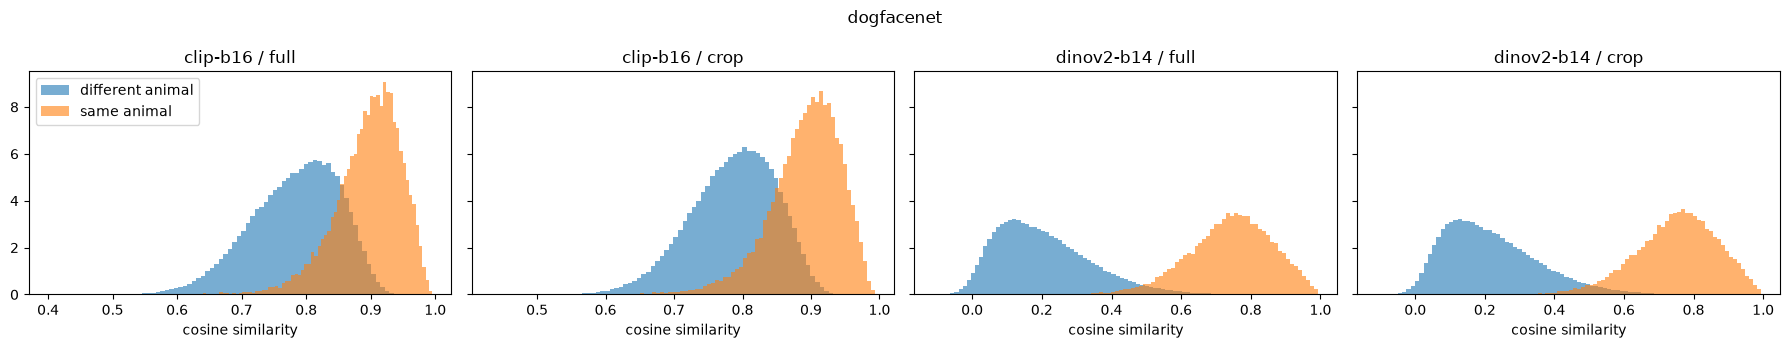

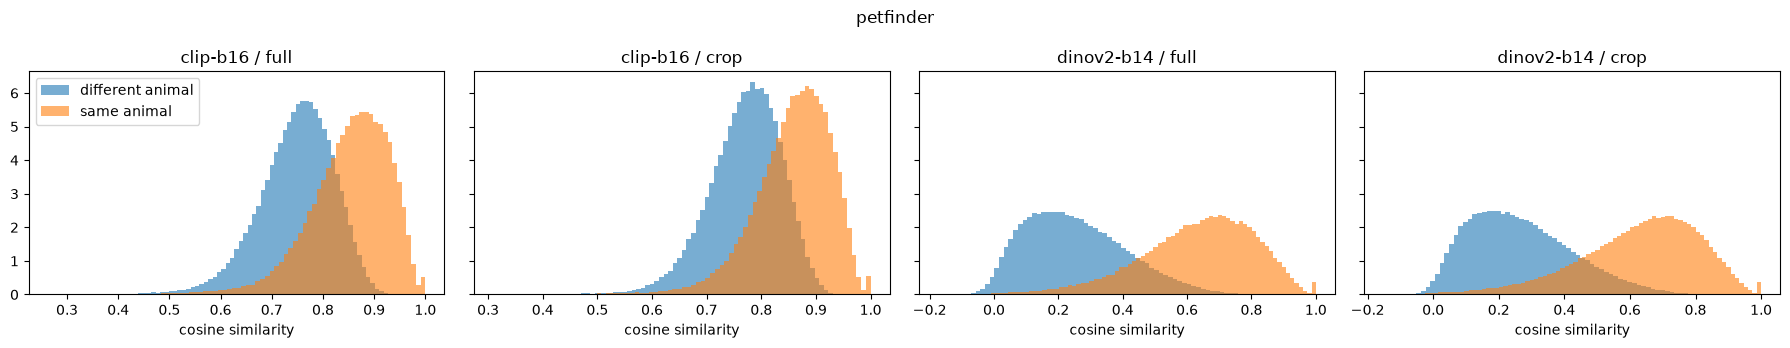

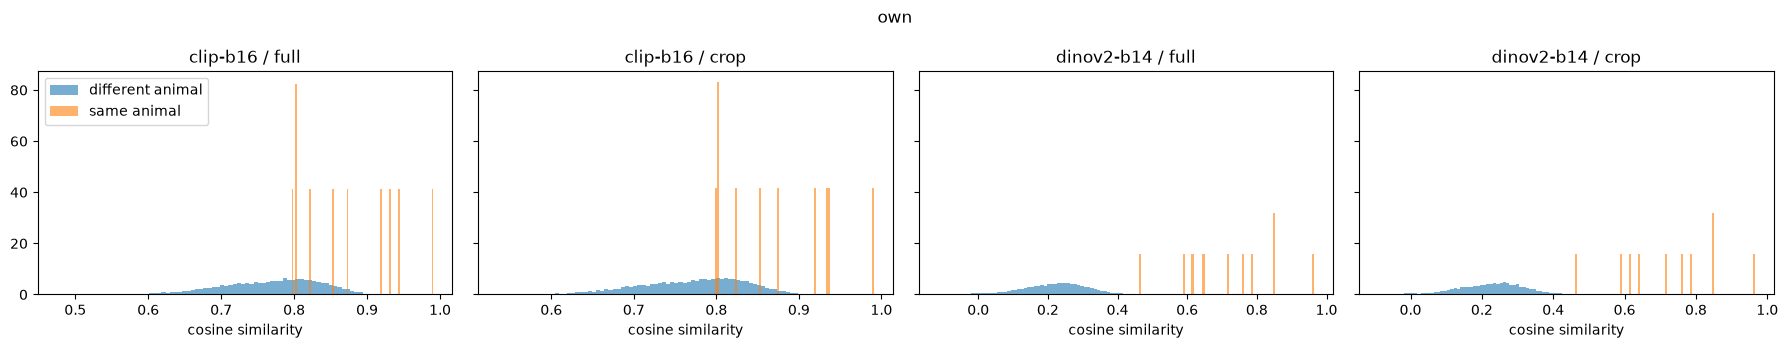

In [5]:
for name in IDENTITY_SETS:
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
    for ax, (model, crop) in zip(axes, [(m, c) for m in MODELS for c in CROPS]):
        pos, neg = pairs[name, model, crop]
        ax.hist(neg, bins=80, density=True, alpha=.6, label='different animal')
        ax.hist(pos, bins=80, density=True, alpha=.6, label='same animal')
        ax.set_title(f'{model} / {crop}'); ax.set_xlabel('cosine similarity')
    axes[0].legend(); fig.suptitle(name); fig.tight_layout()
    fig.savefig(OUT / f'similarity_{name}.png', dpi=110)

## 5. Threshold suggestions
For each target false-positive rate: the cosine threshold, the share of true matches kept (recall), and the expected number of false alerts when one new photo is compared against 100 candidate photos (roughly a geo/time-filtered pool).

In [6]:
best = results.sort_values(['dataset', 'top1', 'auc'], ascending=[True, False, False]).groupby('dataset').head(1)
for r in best.itertuples():
    print(f'\n{r.dataset}: {r.model} / {r.crop}')
    display(metrics.threshold_table(*pairs[r.dataset, r.model, r.crop]))


dogfacenet: dinov2-b14 / crop


,target_fpr,threshold,recall,alerts_per_100
0,0.050,0.4717,0.9809,5.0
1,0.010,0.5966,0.8984,1.0
2,0.005,0.6385,0.8330,0.5
3,0.001,0.7142,0.6506,0.1



own: dinov2-b14 / full


,target_fpr,threshold,recall,alerts_per_100
0,0.050,0.3653,1.0,5.00
1,0.010,0.4332,1.0,1.01
2,0.005,0.4753,0.9,0.50
3,0.001,0.5470,0.9,0.10



petfinder: dinov2-b14 / full


,target_fpr,threshold,recall,alerts_per_100
0,0.050,0.5369,0.7314,5.0
1,0.010,0.6518,0.5038,1.0
2,0.005,0.6890,0.4185,0.5
3,0.001,0.7513,0.2761,0.1


## 6. Thresholds for every setting (to compare models on equal footing)

In [7]:
tables = []
for (name, model, crop), (pos, neg) in pairs.items():
    t = metrics.threshold_table(pos, neg)
    t.insert(0, 'setting', f'{name} | {model} | {crop}')
    tables.append(t)
thresholds = pd.concat(tables, ignore_index=True)
thresholds.to_csv(OUT / 'thresholds.csv', index=False)
thresholds[thresholds['target_fpr'] == 0.01]

,setting,target_fpr,threshold,recall,alerts_per_100
1,dogfacenet | clip-b16 | full,0.01,0.9054,0.4803,1.00
5,dogfacenet | clip-b16 | crop,0.01,0.9028,0.4660,1.00
9,dogfacenet | dinov2-b14 | full,0.01,0.5840,0.8977,1.00
13,dogfacenet | dinov2-b14 | crop,0.01,0.5966,0.8984,1.00
17,petfinder | clip-b16 | full,0.01,0.8845,0.3800,1.00
21,petfinder | clip-b16 | crop,0.01,0.8948,0.3288,1.00
25,petfinder | dinov2-b14 | full,0.01,0.6518,0.5038,1.00
29,petfinder | dinov2-b14 | crop,0.01,0.6697,0.4651,1.00
33,own | clip-b16 | full,0.01,0.8891,0.4000,1.01
37,own | clip-b16 | crop,0.01,0.8886,0.4000,1.01


## 7. PetFinder by species (DINOv2)
PetFinder holds real phone photos of shelter animals, the closest match to app conditions. Cats and dogs are evaluated separately because they need different thresholds.

In [8]:
species_rows = []
if 'petfinder' in IDENTITY_SETS:
    for sp in ['cat', 'dog']:
        for crop in CROPS:
            df, emb = load('petfinder', 'dinov2-b14', crop)
            ox_df, ox_emb = load('oxford', 'dinov2-b14', crop)
            a, b = (df['species'] == sp).to_numpy(), (ox_df['species'] == sp).to_numpy()
            all_df = pd.concat([df[a], ox_df[b]], ignore_index=True)
            all_emb = np.vstack([emb[a], ox_emb[b]])
            pos, neg = metrics.pair_similarities(all_emb, all_df)
            t = metrics.threshold_table(pos, neg, target_fprs=(0.01,)).iloc[0]
            species_rows.append({'species': sp, 'crop': crop, **metrics.retrieval_topk(all_emb, all_df),
                                 'auc': metrics.verification_auc(pos, neg),
                                 'thr_at_1pct_fpr': t['threshold'], 'recall_at_thr': t['recall']})
by_species = pd.DataFrame(species_rows).round(3)
by_species.to_csv(OUT / 'petfinder_by_species.csv', index=False)
by_species

,species,crop,queries,top1,top5,auc,thr_at_1pct_fpr,recall_at_thr
0,cat,full,22756,0.545,0.674,0.908,0.688,0.440
1,cat,crop,22756,0.498,0.628,0.895,0.709,0.396
2,dog,full,25786,0.700,0.819,0.955,0.580,0.637
3,dog,crop,25786,0.660,0.782,0.944,0.593,0.604


## 8. Realistic candidate pools
In the app a sighting is only compared with lost reports inside the geo radius and time window, i.e. tens to a few hundred animals, not thousands. Each report is scored by its best photo. How often does the true animal rank first / in the top 3?

In [9]:
pool_rows = []
if 'petfinder' in IDENTITY_SETS:
    for sp in ['cat', 'dog']:
        for crop in CROPS:
            df, emb = load('petfinder', 'dinov2-b14', crop)
            a = (df['species'] == sp).to_numpy()
            row = {'species': sp, 'crop': crop}
            for n in (50, 200):
                row.update(metrics.candidate_pool_accuracy(emb[a], df[a].reset_index(drop=True), n))
            pool_rows.append(row)
pools = pd.DataFrame(pool_rows).round(3)
pools.to_csv(OUT / 'candidate_pools.csv', index=False)
pools

,species,crop,pool50_top1,pool50_top3,pool200_top1,pool200_top3
0,cat,full,0.852,0.933,0.756,0.856
1,cat,crop,0.827,0.922,0.729,0.828
2,dog,full,0.938,0.974,0.891,0.946
3,dog,crop,0.921,0.964,0.867,0.934
